# **Lab 7 – Laplacian Filter & Mathematical / Statistical Filters**

**Student Name:** Danyal Salman Alhashem  
**Student ID:** 2240002713

- Part A: Laplacian Filter
- Part B: Mathematical and Statistical Filters

# **Part A – Laplacian Filter**

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)




## Apply Laplacian Filter on Image to get Sharp Image

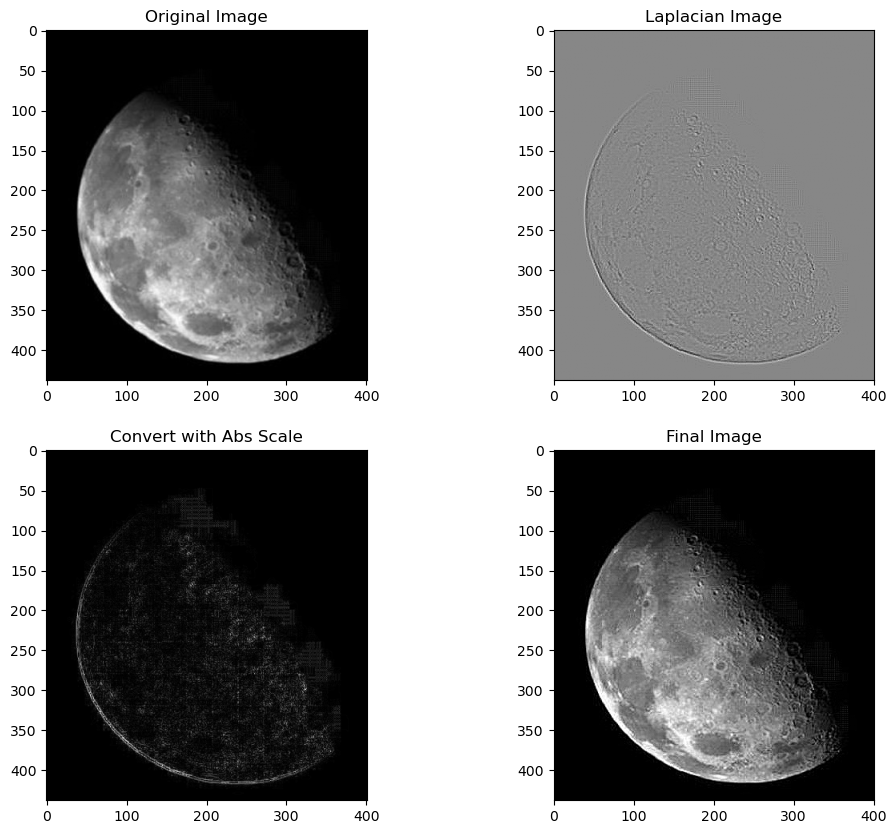

In [2]:

# ================ ( Laplacian Filter ) ===================


# 0. Image file path
imgFile = "images/moon.jpg"

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Manually define the Laplacian Kernel
# This is the standard 3x3 kernel that detects horizontal and vertical edges
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Alternative kernel: Detects diagonal edges as well
# manual_kernel = np.array([
#     [1,  1,  1],
#     [1, -8,  1],
#     [1,  1,  1]
# ], dtype=np.float32)

# 3. Apply the filter using filter2D
# -1 indicates the output image will have the same depth as the source
# However, for Laplacian, use cv2.CV_64F to avoid clipping negative values
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

# Sharpening: g(x,y) = f(x,y) - Laplacian  (because the kernel centre is negative, -4)
# Work in float and clip, so uint8 values do not wrap around (e.g. 250 + 10 -> 4)
finalImage = np.clip(img.astype(np.float64) - laplacian_manual, 0, 255).astype(np.uint8)

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage, cmap='gray'), plt.title('Final Image')
plt.show()


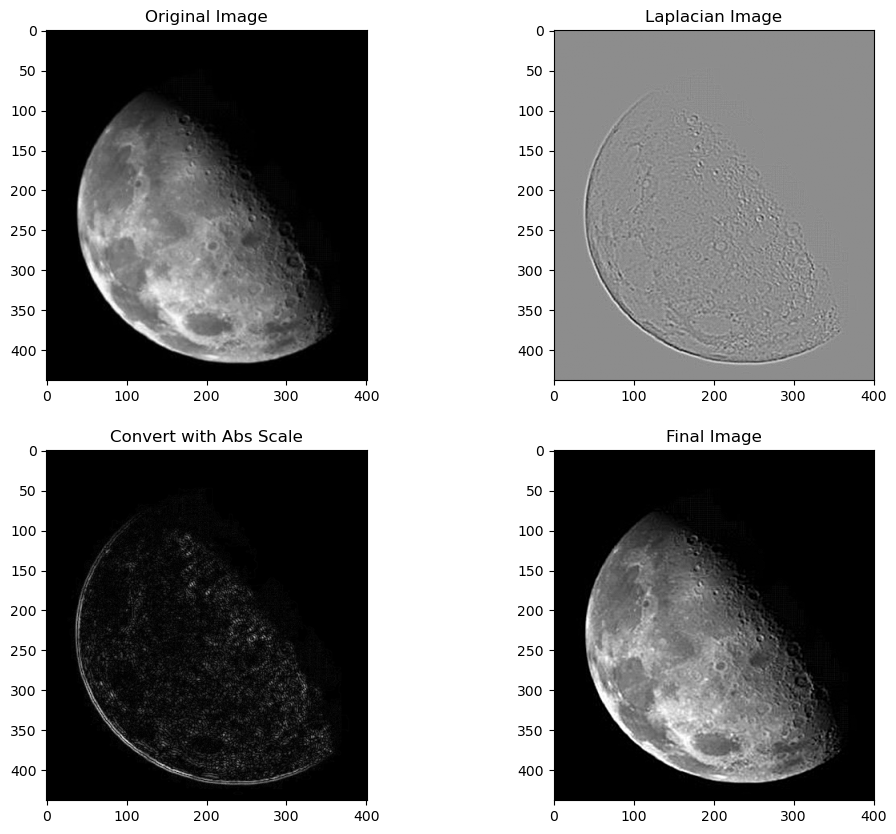

In [3]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Apply Gaussian Blur to reduce noise
# This prevents the algorithm from picking up tiny details as edges
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian Algorithm
# Use CV_64F to capture both positive and negative gradients (essential for edges)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Adding Laplace and origianl Image
# Sharpening with the negative-centre Laplacian: subtract it (float + clip to avoid overflow)
finalImage2 = np.clip(img.astype(np.float64) - laplacian, 0, 255).astype(np.uint8)

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'), plt.title('Final Image')
plt.show()




## Comparing the two Laplacian kernels (4-neighbour vs 8-neighbour)

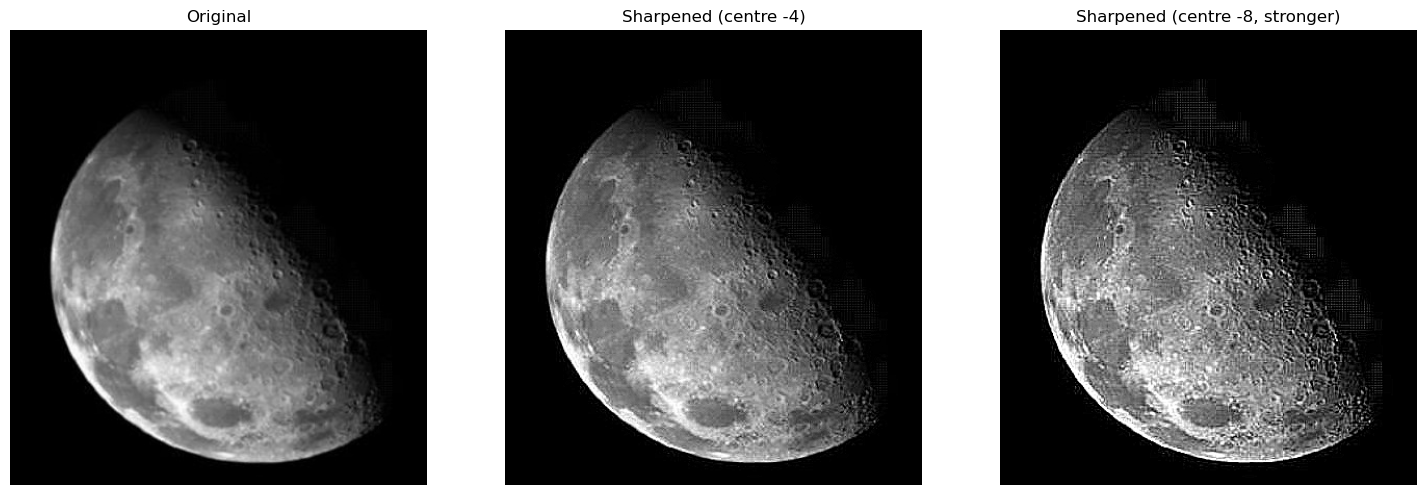

In [4]:
# Compare the standard kernel (centre -4) with the diagonal kernel (centre -8)
k4 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)
k8 = np.array([[1, 1, 1], [1, -8, 1], [1, 1, 1]], dtype=np.float32)

lap4 = cv2.filter2D(img, cv2.CV_64F, k4)
lap8 = cv2.filter2D(img, cv2.CV_64F, k8)
sharp4 = np.clip(img.astype(np.float64) - lap4, 0, 255).astype(np.uint8)
sharp8 = np.clip(img.astype(np.float64) - lap8, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(132), plt.imshow(sharp4, cmap='gray'), plt.title('Sharpened (centre -4)')
plt.subplot(133), plt.imshow(sharp8, cmap='gray'), plt.title('Sharpened (centre -8, stronger)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## Laplacian on a second image (shapes) – edge detection

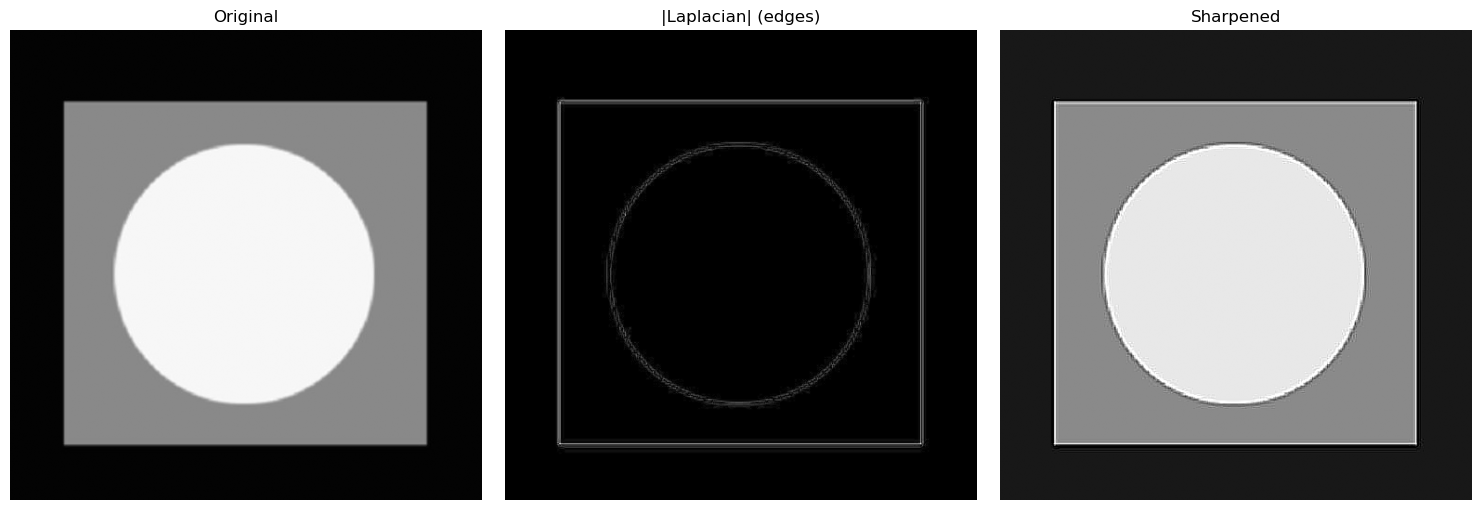

In [5]:
# The Laplacian responds only where intensity changes, so on a flat-region image
# it outputs the outlines of the square and the circle.
shapes = cv2.imread("images/shapes.jpg", 0)
lap_s = cv2.Laplacian(shapes, cv2.CV_64F, ksize=3)
lap_s_abs = cv2.convertScaleAbs(lap_s)
sharp_s = np.clip(shapes.astype(np.float64) - lap_s, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(shapes, cmap='gray'), plt.title('Original')
plt.subplot(132), plt.imshow(lap_s_abs, cmap='gray'), plt.title('|Laplacian| (edges)')
plt.subplot(133), plt.imshow(sharp_s, cmap='gray'), plt.title('Sharpened')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## Conclusion

- The Laplacian is a **second-derivative** filter: it is zero in flat regions and large at edges and fine details (craters on the moon, outlines of the shapes).
- The output contains **negative values**, so it must be computed with `cv2.CV_64F`; `convertScaleAbs` is only used to *display* it.
- Sharpening: **g = f − ∇²f** when the kernel centre is negative (−4 or −8), and g = f + ∇²f when it is positive.
- Adding images directly in `uint8` (`img + laplacian_abs`) **overflows** (values above 255 wrap around to dark pixels), so the sum is done in float and clipped to [0, 255].
- The −8 kernel also includes diagonal neighbours, so it gives stronger sharpening than the −4 kernel.
- A small Gaussian blur before the Laplacian (second cell) reduces noise amplification, giving cleaner edges.

# **Part B – Mathematical and Statistical Filters**

In [6]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)
np.random.seed(0)  # reproducible noise

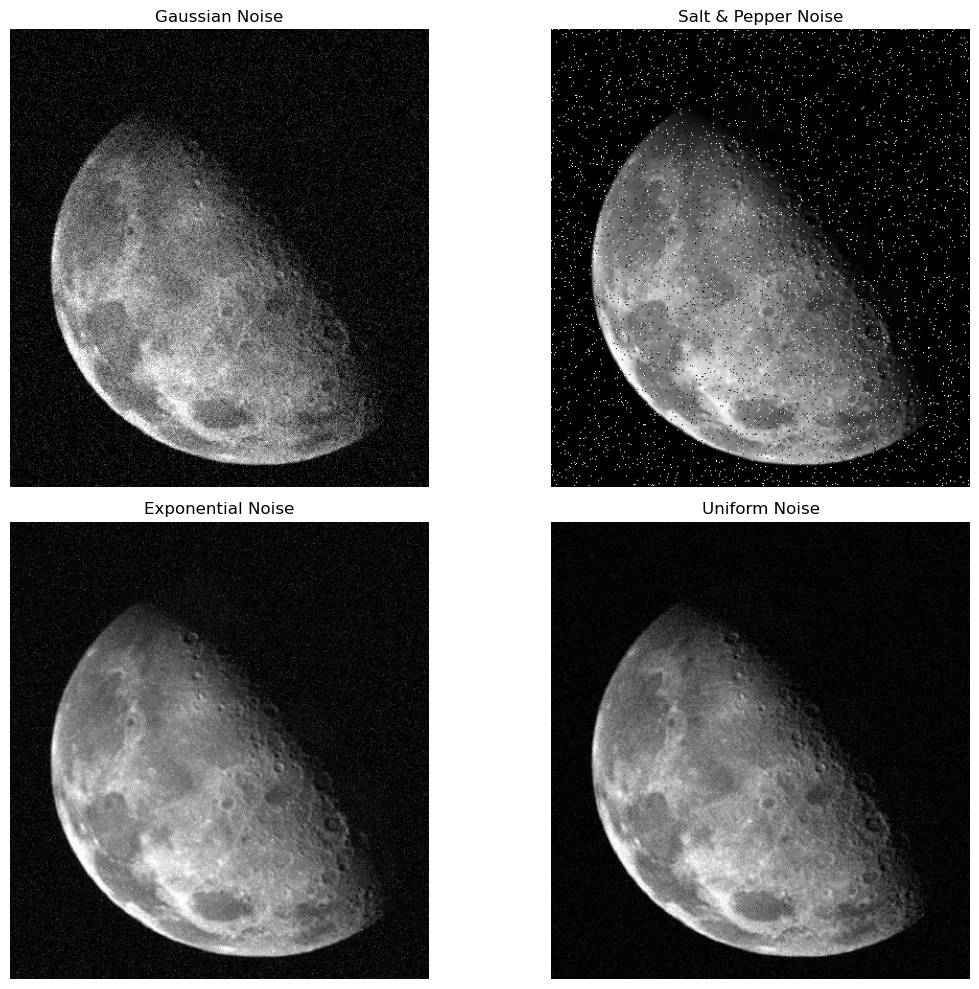

In [7]:
# ========== ( Adding nosie to an Image ) =================

# 0. Read an Image
imgPath = 'images/noise.jpg'
img = cv2.imread(imgPath, 0)

# 1. Function that handle all noise algorithm (Guassian, Exp, Uniform & Salt&Pepper)
def add_noise(image, noise_type):
    row, col = image.shape

    if noise_type == "gaussian":
        mean = 0
        var = 0.01  # Adjust for more/less noise
        sigma = var**0.5
        gauss = np.random.normal(mean, sigma, (row, col))
        noisy = image / 255 + gauss
        return np.clip(noisy * 255, 0, 255).astype(np.uint8)

    elif noise_type == "salt_pepper":
        s_vs_p = 0.5
        amount = 0.04
        noisy = np.copy(image)
        # Salt (white pixels)
        num_salt = np.ceil(amount * image.size * s_vs_p)
        coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
        noisy[tuple(coords)] = 255
        # Pepper (black pixels)
        num_pepper = np.ceil(amount * image.size * (1.0 - s_vs_p))
        coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
        noisy[tuple(coords)] = 0
        return noisy

    elif noise_type == "exponential":
        # Scale is the inverse of the rate (lambda)
        expo = np.random.exponential(scale=10.0, size=(row, col))
        noisy = image + expo
        return np.clip(noisy, 0, 255).astype(np.uint8)

    elif noise_type == "uniform":
        low = -20
        high = 20
        uni = np.random.uniform(low, high, (row, col))
        noisy = image + uni
        return np.clip(noisy, 0, 255).astype(np.uint8)



# 2. Load image in grayscale
img = cv2.imread(imgPath, 0)

# 3. Generate Noisy Images
noise_gauss = add_noise(img, "gaussian")
noise_sp = add_noise(img, "salt_pepper")
noise_expo = add_noise(img, "exponential")
noise_uni = add_noise(img, "uniform")

# 4. Display in 2x2 Grid
plt.figure(figsize=(12, 10))

plt.subplot(221), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(222), plt.imshow(noise_sp, cmap='gray'), plt.title('Salt & Pepper Noise')
plt.subplot(223), plt.imshow(noise_expo, cmap='gray'), plt.title('Exponential Noise')
plt.subplot(224), plt.imshow(noise_uni, cmap='gray'), plt.title('Uniform Noise')

for i in range(1, 5):
    plt.subplot(220 + i).axis('off')

plt.tight_layout()
plt.show()


## **Arithmetic Mean Filter**

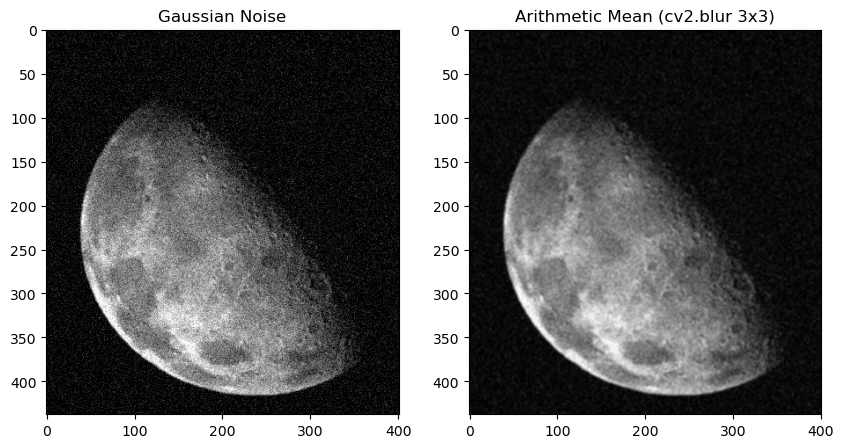

In [8]:
# --- METHOD 1: Using Built-in OpenCV function ---

# 2. Apply Arithmetic Mean Filter (3x3 window)
# The larger the kernel, the smoother (and blurrier) the image becomes.
filtered_img = cv2.blur(noise_gauss, (3, 3))

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_gauss, cmap='gray'), plt.title('Gaussian Noise')
plt.subplot(122), plt.imshow(filtered_img, cmap='gray'), plt.title('Arithmetic Mean (cv2.blur 3x3)')
plt.show()

## **Arithmetic Mean – Manual Kernel**

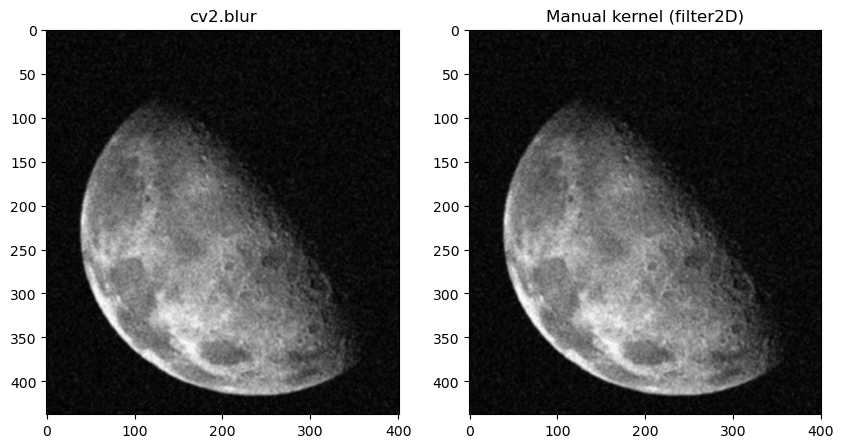

Max difference between the two methods: 0


In [9]:
# --- METHOD 2: Manual implementation using a Kernel ---

# An Arithmetic Mean kernel is just a matrix of 1s divided by the total number of pixels.
kernel_size = 3
kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
arithmetic_mean_manual = cv2.filter2D(noise_gauss, -1, kernel)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(filtered_img, cmap='gray'), plt.title('cv2.blur')
plt.subplot(122), plt.imshow(arithmetic_mean_manual, cmap='gray'), plt.title('Manual kernel (filter2D)')
plt.show()
print("Max difference between the two methods:",
      np.abs(filtered_img.astype(int) - arithmetic_mean_manual.astype(int)).max())

## **Geometric Means**

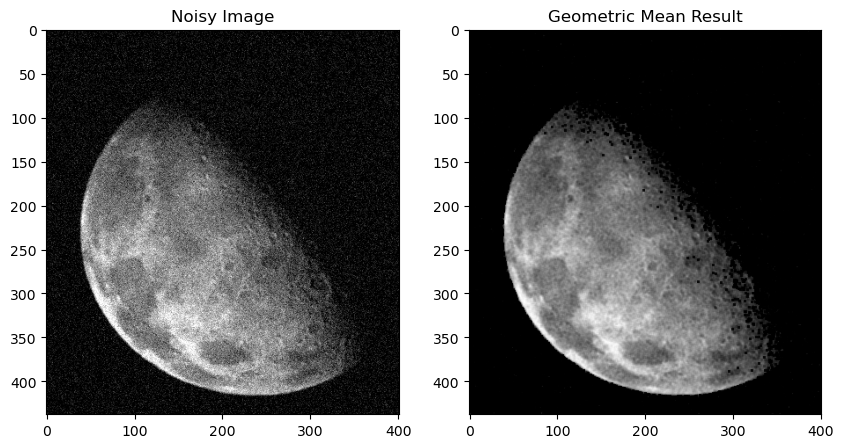

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def geometric_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 and add a tiny epsilon to avoid log(0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Apply the log-transform
    log_img = np.log(img_float)

    # 3. Apply a box filter to the log image (calculates the average of logs)
    kernel = np.ones((kernel_size, kernel_size), np.float32) / (kernel_size * kernel_size)
    mean_log = cv2.filter2D(log_img, -1, kernel)

    # 4. Take the exponent to get back to the geometric mean
    geo_mean = np.exp(mean_log)

    # 5. Clip and convert back to 8-bit
    return np.clip(geo_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_gauss

# Apply filter
result = geometric_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(result, cmap='gray'), plt.title('Geometric Mean Result')
plt.show()


## **Harmonic Means Filter**

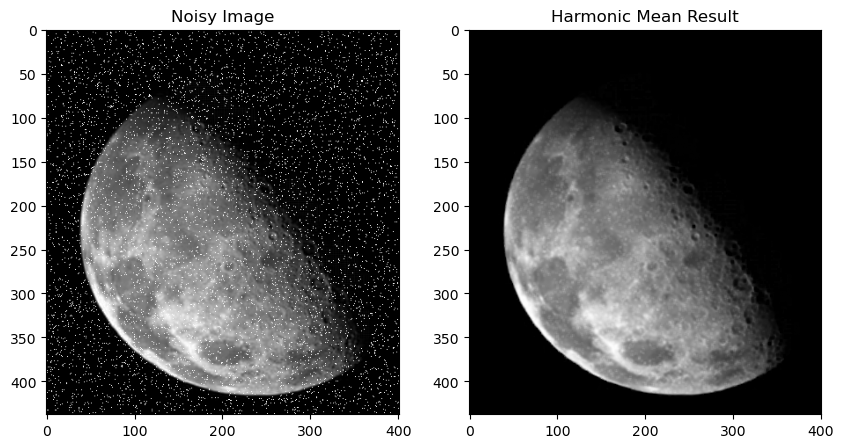

In [11]:

def harmonic_mean_filter(image, kernel_size=3):
    # 1. Convert to float64 to avoid overflow during calculation
    # Add a tiny epsilon to handle black pixels (0)
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate the reciprocal of every pixel (1/P)
    reciprocal_img = 1.0 / img_float

    # 3. Sum the reciprocals in a window and divide by window size
    # This is equivalent to applying a standard mean filter to the reciprocal image
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    sum_reciprocal = cv2.filter2D(reciprocal_img, -1, kernel)

    # 4. Final step of the formula: (Window Size) / Sum of Reciprocals
    # Note: Window size is kernel_size * kernel_size
    n = kernel_size * kernel_size
    harmonic_mean = n / sum_reciprocal

    # 5. Clip the results and convert back to 8-bit
    return np.clip(harmonic_mean, 0, 255).astype(np.uint8)


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

# Harmonic mean works well on SALT noise (and Gaussian), but fails on pepper.
# Build a salt-only noisy image (4% white pixels) to show this.
noise_img = img.copy()
noise_img[np.random.rand(*img.shape) < 0.04] = 255

# Apply the filter
cleaned_img = harmonic_mean_filter(noise_img, kernel_size=3)

# Display Comparison
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Noisy Image')
plt.subplot(122), plt.imshow(cleaned_img, cmap='gray'), plt.title('Harmonic Mean Result')
plt.show()


## **Contra - Harmonic Mean Filter**

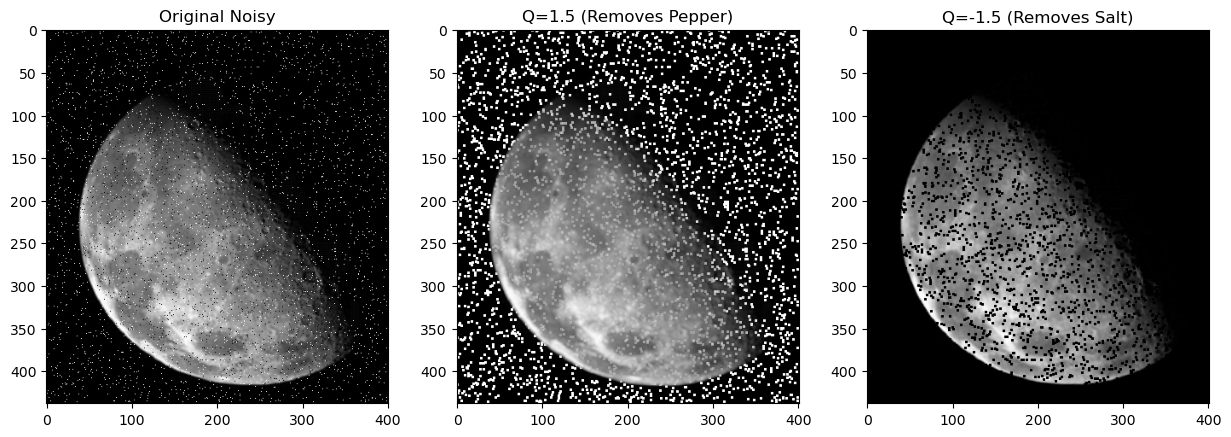

In [12]:


def contra_harmonic_mean(image, kernel_size=3, Q=0):
    # 1. Convert to float to handle high powers and prevent overflow
    img_float = image.astype(np.float64) + 1e-6

    # 2. Calculate numerator: Sum of pixels to the power (Q + 1)
    numerator = np.power(img_float, Q + 1)
    kernel = np.ones((kernel_size, kernel_size), np.float32)
    num_sum = cv2.filter2D(numerator, -1, kernel)

    # 3. Calculate denominator: Sum of pixels to the power (Q)
    denominator = np.power(img_float, Q)
    den_sum = cv2.filter2D(denominator, -1, kernel)

    # 4. Divide and clean up
    # Handle potential division by zero
    result = num_sum / (den_sum + 1e-6)

    return np.clip(result, 0, 255).astype(np.uint8)

# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_sp

# --- APPLICATIONS ---
# Q > 0 (e.g., 1.5): Removes Pepper Noise (black spots)
pepper_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=1.5)

# Q < 0 (e.g., -1.5): Removes Salt Noise (white spots)
salt_removed = contra_harmonic_mean(noise_img, kernel_size=3, Q=-1.5)

# --- DISPLAY ---
plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(pepper_removed, cmap='gray'), plt.title('Q=1.5 (Removes Pepper)')
plt.subplot(133), plt.imshow(salt_removed, cmap='gray'), plt.title('Q=-1.5 (Removes Salt)')
plt.show()


## **Median Filter**

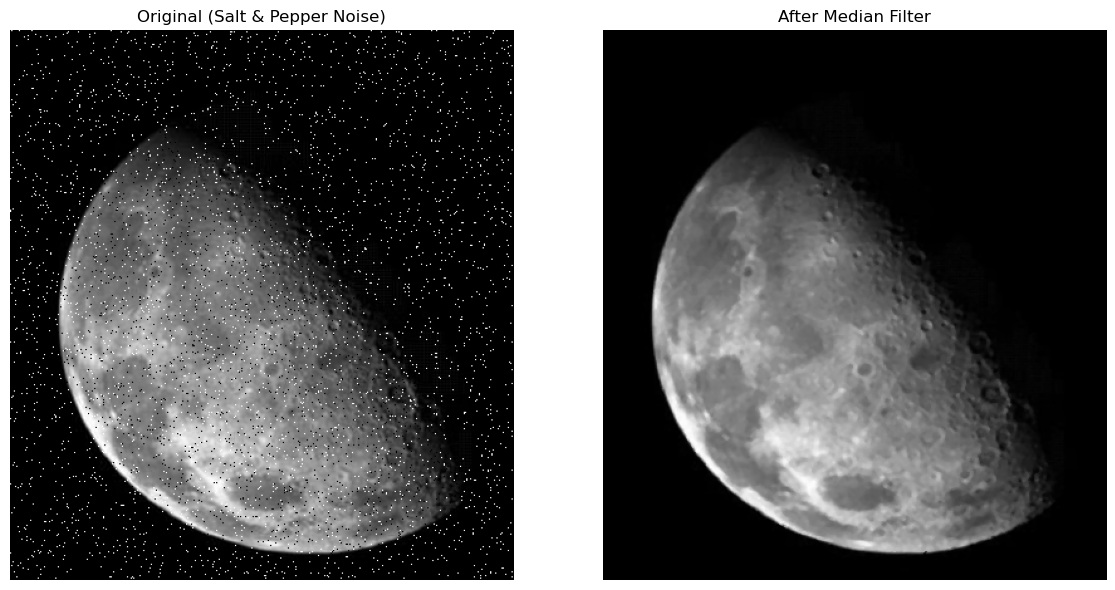

In [13]:



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_sp

# 2. Apply Median Filter
# The second argument is the 'ksize' (kernel size).
# It MUST be an odd integer (3, 5, 7, etc.)
median_result = cv2.medianBlur(noise_img, 3)

# 3. Compare Results
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Original (Salt & Pepper Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(median_result, cmap='gray'), plt.title('After Median Filter'), plt.axis('off')
plt.tight_layout()
plt.show()


## **Max and Min Filter**

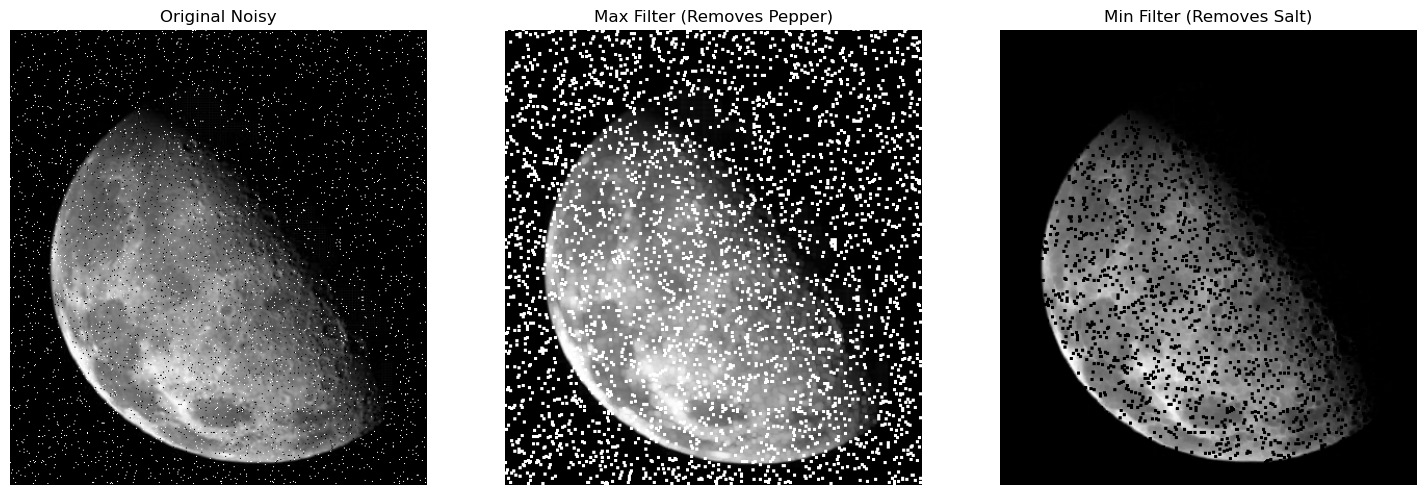

In [14]:


# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_sp



# 2. Define the Kernel size (e.g., 3x3)
kernel = np.ones((3, 3), np.uint8)

# 3. Apply Max Filter (Dilation)
# This picks the brightest pixel in the neighborhood.
max_filter = cv2.dilate(noise_img, kernel)

# 4. Apply Min Filter (Erosion)
# This picks the darkest pixel in the neighborhood.
min_filter = cv2.erode(noise_img, kernel)

# --- Display Results ---
plt.figure(figsize=(15, 5))

plt.subplot(131), plt.imshow(noise_img, cmap='gray'), plt.title('Original Noisy')
plt.subplot(132), plt.imshow(max_filter, cmap='gray'), plt.title('Max Filter (Removes Pepper)')
plt.subplot(133), plt.imshow(min_filter, cmap='gray'), plt.title('Min Filter (Removes Salt)')

for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()


## **Mid-Point Filtering**

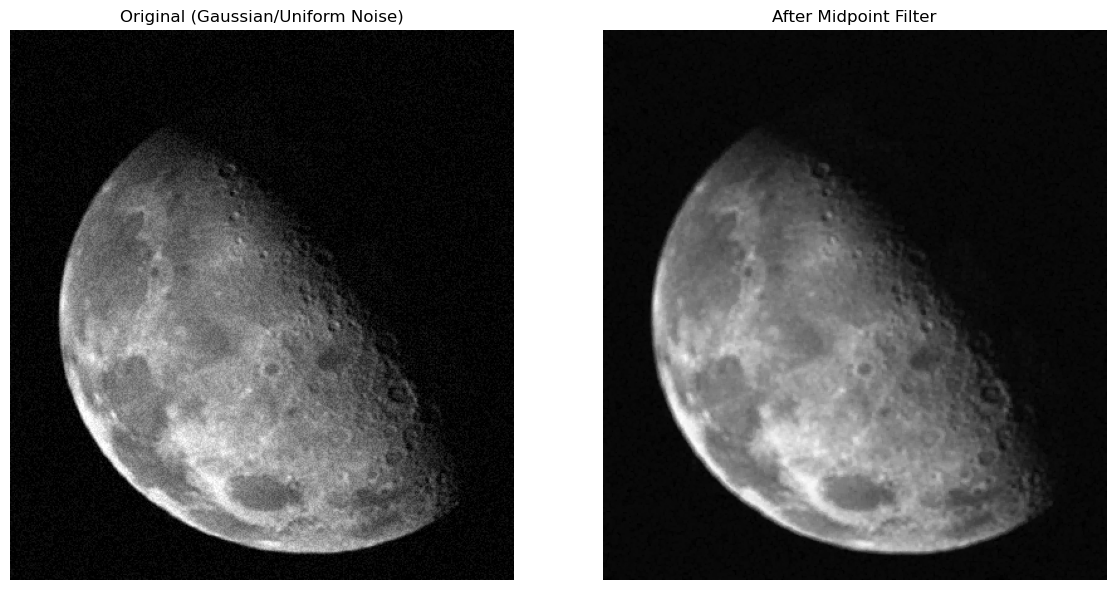

In [15]:

def midpoint_filter(image, kernel_size=3):
    # 1. Define the structural element (kernel)
    kernel = np.ones((kernel_size, kernel_size), np.uint8)

    # 2. Find the Maximum value in the neighborhood (Dilation)
    max_img = cv2.dilate(image, kernel).astype(np.float64)

    # 3. Find the Minimum value in the neighborhood (Erosion)
    min_img = cv2.erode(image, kernel).astype(np.float64)

    # 4. Calculate the average of Max and Min
    midpoint = (max_img + min_img) / 2

    # 5. Convert back to 8-bit
    return midpoint.astype(np.uint8)



# === List of noisy images
# noise_gauss = add_noise(img, "gaussian")
# noise_sp = add_noise(img, "salt_pepper")
# noise_expo = add_noise(img, "exponential")
# noise_uni = add_noise(img, "uniform")

noise_img = noise_uni


# Apply the Midpoint Filter
result = midpoint_filter(noise_img, kernel_size=3)

# --- Display Results ---
plt.figure(figsize=(12, 6))

plt.subplot(121), plt.imshow(noise_img, cmap='gray'), plt.title('Original (Gaussian/Uniform Noise)'), plt.axis('off')
plt.subplot(122), plt.imshow(result, cmap='gray'), plt.title('After Midpoint Filter'), plt.axis('off')

plt.tight_layout()
plt.show()


## **Comparison of all filters (PSNR vs clean image)**

In [16]:
import pandas as pd

def psnr(a, b):
    return cv2.PSNR(a, b)

noises = {"Gaussian": noise_gauss, "Salt & Pepper": noise_sp,
          "Exponential": noise_expo, "Uniform": noise_uni}
filters = {
    "Noisy (no filter)": lambda x: x,
    "Arithmetic": lambda x: cv2.blur(x, (3, 3)),
    "Geometric": geometric_mean_filter,
    "Harmonic": harmonic_mean_filter,
    "Contra-harm Q=1.5": lambda x: contra_harmonic_mean(x, 3, 1.5),
    "Contra-harm Q=-1.5": lambda x: contra_harmonic_mean(x, 3, -1.5),
    "Median": lambda x: cv2.medianBlur(x, 3),
    "Max": lambda x: cv2.dilate(x, np.ones((3, 3), np.uint8)),
    "Min": lambda x: cv2.erode(x, np.ones((3, 3), np.uint8)),
    "Midpoint": midpoint_filter,
}
table = pd.DataFrame({n: {f: psnr(img, fn(nimg)) for f, fn in filters.items()}
                      for n, nimg in noises.items()}).round(2)
print("PSNR in dB (higher = closer to the clean image)")
table

PSNR in dB (higher = closer to the clean image)


,Gaussian,Salt & Pepper,Exponential,Uniform
Noisy (no filter),21.68,17.94,25.34,28.51
Arithmetic,27.81,26.72,27.75,33.55
Geometric,28.59,18.83,30.92,33.99
Harmonic,26.97,17.79,31.60,32.37
Contra-harm Q=1.5,19.57,9.96,22.35,26.81
Contra-harm Q=-1.5,25.82,17.77,31.62,31.24
Median,28.94,40.75,29.50,33.44
Max,15.77,9.24,17.92,22.35
Min,19.41,17.50,29.34,24.36
Midpoint,23.39,15.03,24.48,30.68


## **Applying the filters to the given noisy images (real Salt & Pepper noise)**

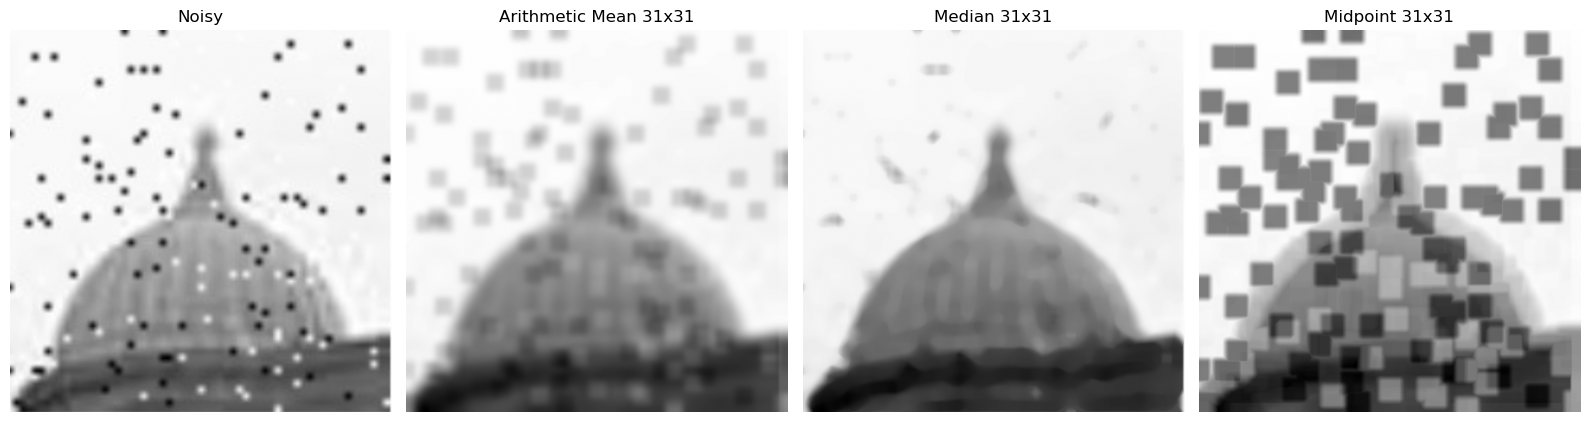

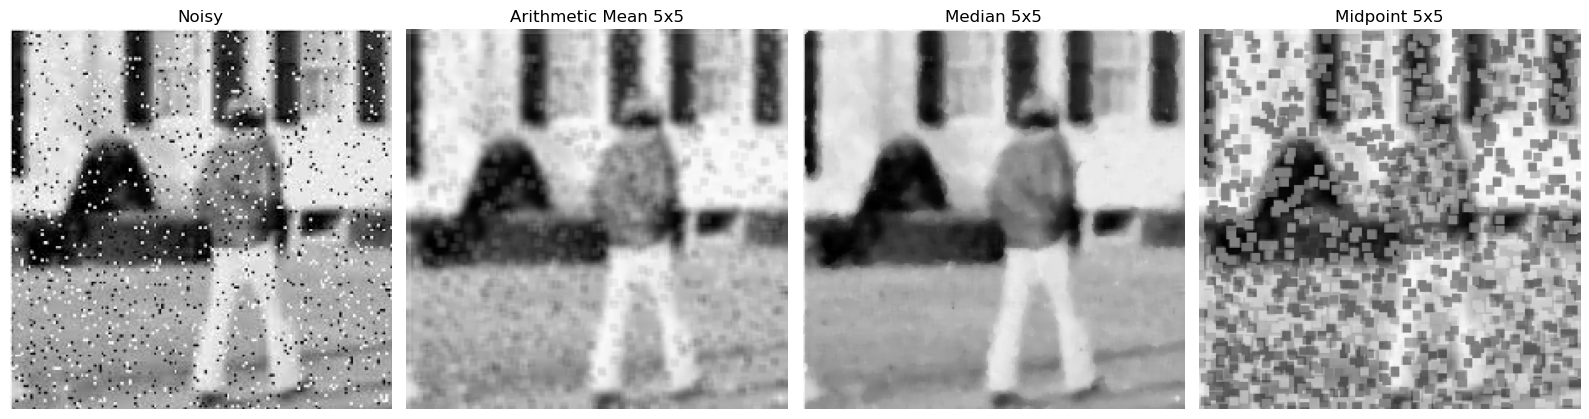

In [17]:
# These two images already contain salt & pepper noise.
# The median window must be about twice the size of a noise dot:
#  - dome image: dots are ~15 px wide (upscaled + blurred) -> 31x31
#  - person image: dots are 1-2 px wide -> 5x5
for path, k in [('images/dome_noisy.jpg', 31), ('images/person_noisy.jpg', 5)]:
    noisy = cv2.imread(path, 0)
    results = {
        "Noisy": noisy,
        f"Arithmetic Mean {k}x{k}": cv2.blur(noisy, (k, k)),
        f"Median {k}x{k}": cv2.medianBlur(noisy, k),
        f"Midpoint {k}x{k}": midpoint_filter(noisy, k),
    }
    plt.figure(figsize=(16, 4.5))
    for i, (t, r) in enumerate(results.items(), 1):
        plt.subplot(1, 4, i), plt.imshow(r, cmap='gray'), plt.title(t), plt.axis('off')
    plt.tight_layout()
    plt.show()

## **Conclusion**

| Filter | Best for | Notes |
|---|---|---|
| Arithmetic mean | Gaussian / uniform noise | Reduces noise but blurs edges |
| Geometric mean | Gaussian noise | Similar smoothing, keeps a bit more detail; a single 0 (pepper) makes the whole window dark |
| Harmonic mean | **Salt** noise, Gaussian | Fails on pepper noise |
| Contra-harmonic Q > 0 | **Pepper** noise | Wrong sign of Q makes noise worse |
| Contra-harmonic Q < 0 | **Salt** noise | |
| Median | **Salt & pepper** (impulse) | Removes impulses and keeps edges – best result in the table |
| Max | Pepper noise | Enlarges salt points |
| Min | Salt noise | Enlarges pepper points |
| Midpoint | Uniform / Gaussian noise | Very bad for salt & pepper (extremes dominate) |

On the given dome and person images, the **median filter** removes the black and white dots almost completely, while the mean filter only spreads them into grey blobs and the midpoint filter makes them worse.